# 03b - Strong Models
Goal: train Random Forest and LightGBM for binary and multi-class detection, handle class imbalance, tune hyperparameters and save the best multi-class model.

## 1. Setup
Load the processed train/test sets and split them into features (X) and labels (y). `FEATURE_COLS` from `src/config.py` fixes the column order, so the saved model gets the same input order in the demo and the Mininet test.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
from src.config import RANDOM_STATE, FEATURE_COLS, LABEL_COLS

TRAIN_PATH = '../data/processed/train.parquet'
TEST_PATH  = '../data/processed/test.parquet'

print('RANDOM_STATE:', RANDOM_STATE)
print('Number of features:', len(FEATURE_COLS))
print('Label columns:', LABEL_COLS)

RANDOM_STATE: 42
Number of features: 62
Label columns: ['label_multi', 'label_binary']


In [2]:
train = pd.read_parquet(TRAIN_PATH)
test  = pd.read_parquet(TEST_PATH)

print('Train:', train.shape)
print('Test: ', test.shape)

Train: (341633, 64)
Test:  (85409, 64)


In [3]:
X_train = train[FEATURE_COLS]
X_test  = test[FEATURE_COLS]

y_train_bin = train['label_binary']
y_test_bin  = test['label_binary']

y_train_multi = train['label_multi']
y_test_multi  = test['label_multi']

print('X_train:', X_train.shape, '| X_test:', X_test.shape)

X_train: (341633, 62) | X_test: (85409, 62)


Class distribution in train and test. Thanks to the stratified split, the percentages should be almost the same in both sets.

In [4]:
dist = pd.DataFrame({
    'train_count': y_train_multi.value_counts(),
    'train_%': (y_train_multi.value_counts(normalize=True) * 100).round(2),
    'test_count': y_test_multi.value_counts(),
    'test_%': (y_test_multi.value_counts(normalize=True) * 100).round(2),
})
dist

,train_count,train_%,test_count,test_%
label_multi,,,,
Benign,186996,54.74,46749,54.74
Dos,101205,29.62,25301,29.62
DDoS,40215,11.77,10054,11.77
Bot,7165,2.10,1792,2.10
Prob,6052,1.77,1513,1.77


In [5]:
print('Binary labels (0 = Benign, 1 = Attack), train %:')
print((y_train_bin.value_counts(normalize=True) * 100).round(2))

Binary labels (0 = Benign, 1 = Attack), train %:
label_binary
0    54.74
1    45.26
Name: proportion, dtype: float64


## 2. evaluate()
Copied unchanged from `notebooks/03_models.ipynb` (baseline-models branch, commit e343c28), so all models are measured in the same way.

It trains the model, measures training time and prediction time per flow (ms), prints the classification report and returns one row for the results table. The function always returns `imbalance='none'` and empty `notes`, so we set these fields on the returned row when needed. It does not return the predictions, so for confusion matrices we call `model.predict` again on the already trained model.

In [6]:
import time
from sklearn.metrics import f1_score, accuracy_score, classification_report

In [7]:
def evaluate(model, name, task, X_tr, y_tr, X_te, y_te):
    # 1) train and measure time
    t0 = time.perf_counter()
    model.fit(X_tr,y_tr)
    train_time = time.perf_counter() - t0

    # 2) predict and measure time
    t0 = time.perf_counter()
    y_pred = model.predict(X_te)
    predict_time = time.perf_counter() - t0
    predict_ms = predict_time / len(X_te) * 1000 #converts seconds to ms

    # 3) show the detailed report
    print(f"=== {name} | {task} ===")
    print(classification_report(y_te,y_pred,digits=4))

    # 4) return one row for results.csv
    return{
        "model":name,
        "task":task,
        "imbalance":"none",
        "macro_f1":f1_score(y_te,y_pred,average="macro"),
        "accuracy":accuracy_score(y_te,y_pred),
        "train_time_s":round(train_time,2),
        "predict_ms_per_flow":round(predict_ms,5),
        "notes":"",

    }


In [8]:
results = []  # one dict per model, written to reports/results_strong.csv at the end

## 3. Random Forest
Random Forest trains many decision trees, each on a bootstrap sample of the rows and a random subset of features at each split, and takes a majority vote. Averaging many different trees reduces overfitting compared to a single tree.

No scaler: a tree splits on thresholds such as `Flow Duration > 1000`, so the scale of a feature does not change which split is chosen. Default hyperparameters are used here (100 trees); tuning comes in section 6. `n_jobs=-1` uses all CPU cores.

In [9]:
from sklearn.ensemble import RandomForestClassifier

In [10]:
rf_bin = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

row = evaluate(rf_bin, "RandomForest", "binary",
               X_train, y_train_bin, X_test, y_test_bin)
results.append(row)
row

=== RandomForest | binary ===
              precision    recall  f1-score   support

           0     0.9213    0.9199    0.9206     46749
           1     0.9033    0.9049    0.9041     38660

    accuracy                         0.9131     85409
   macro avg     0.9123    0.9124    0.9124     85409
weighted avg     0.9131    0.9131    0.9131     85409



{'model': 'RandomForest',
 'task': 'binary',
 'imbalance': 'none',
 'macro_f1': 0.9123512667967151,
 'accuracy': 0.9131239096582328,
 'train_time_s': 11.19,
 'predict_ms_per_flow': 0.00224,
 'notes': ''}

In [11]:
rf_multi = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

row = evaluate(rf_multi, "RandomForest", "multi",
               X_train, y_train_multi, X_test, y_test_multi)
results.append(row)
row

=== RandomForest | multi ===


              precision    recall  f1-score   support

      Benign     0.9195    0.9212    0.9203     46749
         Bot     0.2926    0.2896    0.2911      1792
        DDoS     0.5634    0.5651    0.5643     10054
         Dos     0.9106    0.9096    0.9101     25301
        Prob     0.5521    0.5254    0.5384      1513

    accuracy                         0.8556     85409
   macro avg     0.6476    0.6422    0.6448     85409
weighted avg     0.8553    0.8556    0.8554     85409



{'model': 'RandomForest',
 'task': 'multi',
 'imbalance': 'none',
 'macro_f1': 0.6448476159595093,
 'accuracy': 0.8555889894507605,
 'train_time_s': 11.75,
 'predict_ms_per_flow': 0.0028,
 'notes': ''}

## 4. LightGBM
LightGBM is a gradient boosting model. Unlike Random Forest, where trees are trained independently and vote, boosting trains small trees one after another and each new tree tries to correct the errors of the trees before it. LightGBM is fast because it bins feature values into histograms and grows each tree leaf by leaf.

Same setup as Random Forest for a fair comparison: default hyperparameters and no scaler (also tree-based). `verbose=-1` only hides LightGBM's training log.

In [12]:
from lightgbm import LGBMClassifier

In [13]:
lgbm_bin = LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)

row = evaluate(lgbm_bin, "LightGBM", "binary",
               X_train, y_train_bin, X_test, y_test_bin)
results.append(row)
row

=== LightGBM | binary ===
              precision    recall  f1-score   support

           0     0.9817    0.8932    0.9353     46749
           1     0.8835    0.9798    0.9292     38660

    accuracy                         0.9324     85409
   macro avg     0.9326    0.9365    0.9322     85409
weighted avg     0.9372    0.9324    0.9325     85409



{'model': 'LightGBM',
 'task': 'binary',
 'imbalance': 'none',
 'macro_f1': 0.9322447775503686,
 'accuracy': 0.9323841749698509,
 'train_time_s': 1.78,
 'predict_ms_per_flow': 0.00094,
 'notes': ''}

In [14]:
lgbm_multi = LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)

row = evaluate(lgbm_multi, "LightGBM", "multi",
               X_train, y_train_multi, X_test, y_test_multi)
results.append(row)
row

=== LightGBM | multi ===


              precision    recall  f1-score   support

      Benign     0.9468    0.9238    0.9352     46749
         Bot     0.4381    0.0552    0.0981      1792
        DDoS     0.5717    0.8355    0.6788     10054
         Dos     0.9585    0.9074    0.9322     25301
        Prob     0.7798    0.4752    0.5906      1513

    accuracy                         0.8824     85409
   macro avg     0.7390    0.6394    0.6470     85409
weighted avg     0.8925    0.8824    0.8805     85409



{'model': 'LightGBM',
 'task': 'multi',
 'imbalance': 'none',
 'macro_f1': 0.6469781637595247,
 'accuracy': 0.8823777353674671,
 'train_time_s': 5.13,
 'predict_ms_per_flow': 0.00301,
 'notes': ''}

## 5. Class imbalance
Bot (2.1%) and Prob (1.8%) are rare. In section 4, LightGBM predicted 86% of Bot flows as DDoS: the two classes look similar and DDoS has 5.6 times more training rows, so the majority class is the safer guess.

`class_weight="balanced"` gives each class a weight of `n_samples / (n_classes * n_samples_in_class)`, so mistakes on rare classes cost more during training. It does not add or remove rows and is applied to the training data only.

The `none` results are already in sections 3 and 4. Here we train the `balanced` versions of both models for both tasks. `evaluate()` always returns `imbalance='none'`, so we set the field on the returned row.

In [15]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train_multi)
weights = compute_class_weight("balanced", classes=classes, y=y_train_multi)
pd.Series(weights, index=classes).round(2).sort_values()

Benign     0.37
Dos        0.68
DDoS       1.70
Bot        9.54
Prob      11.29
dtype: float64

In [16]:
balanced_models = {
    ("RandomForest", "binary"): RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    ("RandomForest", "multi"):  RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    ("LightGBM", "binary"):     LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
    ("LightGBM", "multi"):      LGBMClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
}

for (name, task), model in balanced_models.items():
    y_tr, y_te = (y_train_bin, y_test_bin) if task == "binary" else (y_train_multi, y_test_multi)
    row = evaluate(model, name, task, X_train, y_tr, X_test, y_te)
    row["imbalance"] = "balanced"
    results.append(row)

=== RandomForest | binary ===
              precision    recall  f1-score   support

           0     0.9214    0.9198    0.9206     46749
           1     0.9032    0.9052    0.9042     38660

    accuracy                         0.9132     85409
   macro avg     0.9123    0.9125    0.9124     85409
weighted avg     0.9132    0.9132    0.9132     85409



=== RandomForest | multi ===


              precision    recall  f1-score   support

      Benign     0.9192    0.9213    0.9203     46749
         Bot     0.2903    0.2907    0.2905      1792
        DDoS     0.5618    0.5636    0.5627     10054
         Dos     0.9110    0.9092    0.9101     25301
        Prob     0.5481    0.5155    0.5313      1513

    accuracy                         0.8552     85409
   macro avg     0.6461    0.6401    0.6430     85409
weighted avg     0.8550    0.8552    0.8551     85409



=== LightGBM | binary ===
              precision    recall  f1-score   support

           0     0.9856    0.8888    0.9347     46749
           1     0.8798    0.9843    0.9291     38660

    accuracy                         0.9320     85409
   macro avg     0.9327    0.9365    0.9319     85409
weighted avg     0.9377    0.9320    0.9322     85409



=== LightGBM | multi ===


              precision    recall  f1-score   support

      Benign     0.9943    0.8734    0.9299     46749
         Bot     0.1900    0.8705    0.3119      1792
        DDoS     0.5100    0.4866    0.4980     10054
         Dos     0.9902    0.8871    0.9358     25301
        Prob     0.2771    0.7092    0.3985      1513

    accuracy                         0.8290     85409
   macro avg     0.5923    0.7654    0.6148     85409
weighted avg     0.9065    0.8290    0.8585     85409



Side-by-side comparison of `none` and `balanced` (macro F1 on the test set).

In [17]:
cmp = pd.DataFrame(results).pivot_table(index=["model", "task"], columns="imbalance", values="macro_f1")
cmp["diff"] = cmp["balanced"] - cmp["none"]
cmp.round(4)

imbalance            balanced    none    diff
model        task                            
LightGBM     binary    0.9319  0.9322 -0.0003
             multi     0.6148  0.6470 -0.0321
RandomForest binary    0.9124  0.9124  0.0000
             multi     0.6430  0.6448 -0.0019

Recall per class for the multi-class models: does `balanced` help Bot and Prob?

In [18]:
from sklearn.metrics import recall_score

multi_models = {
    ("RandomForest", "none"): rf_multi,
    ("RandomForest", "balanced"): balanced_models[("RandomForest", "multi")],
    ("LightGBM", "none"): lgbm_multi,
    ("LightGBM", "balanced"): balanced_models[("LightGBM", "multi")],
}

recall_table = pd.DataFrame({
    key: recall_score(y_test_multi, model.predict(X_test), labels=classes, average=None)
    for key, model in multi_models.items()
}, index=classes).T
recall_table.round(3)

Benign    Bot   DDoS    Dos   Prob
RandomForest none       0.921  0.290  0.565  0.910  0.525
             balanced   0.921  0.291  0.564  0.909  0.516
LightGBM     none       0.924  0.055  0.835  0.907  0.475
             balanced   0.873  0.871  0.487  0.887  0.709

### SMOTE (LightGBM, multi-class)
SMOTE creates synthetic rows for the minority classes by interpolating between a sample and one of its nearest neighbours of the same class. With the default settings every class is oversampled to the size of the largest class (Benign).

SMOTE is put inside an `imblearn.pipeline.Pipeline`, so it runs only during `fit` on the training data. During `predict` the step is skipped and the test set is used as it is.

We only try it for LightGBM multi-class: `balanced` had no effect on Random Forest and on the binary task, where the classes are already close to balanced.

Limitation: SMOTE finds neighbours with Euclidean distance on unscaled features, so large-valued features such as `Flow Duration` dominate the neighbour search.

In [19]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

lgbm_smote = ImbPipeline([
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)),
])

row = evaluate(lgbm_smote, "LightGBM", "multi",
               X_train, y_train_multi, X_test, y_test_multi)
row["imbalance"] = "smote"
results.append(row)
row

=== LightGBM | multi ===


              precision    recall  f1-score   support

      Benign     0.9940    0.8744    0.9304     46749
         Bot     0.1952    0.8594    0.3181      1792
        DDoS     0.5153    0.5148    0.5151     10054
         Dos     0.9894    0.8864    0.9351     25301
        Prob     0.2911    0.7085    0.4127      1513

    accuracy                         0.8324     85409
   macro avg     0.5970    0.7687    0.6223     85409
weighted avg     0.9071    0.8324    0.8609     85409



{'model': 'LightGBM',
 'task': 'multi',
 'imbalance': 'smote',
 'macro_f1': 0.6222580815776257,
 'accuracy': 0.8323712957650833,
 'train_time_s': 22.59,
 'predict_ms_per_flow': 0.00279,
 'notes': ''}

### SMOTE with scaling (LightGBM, multi-class)
To test the limitation above, the same experiment is repeated with a `StandardScaler` before SMOTE: `StandardScaler → SMOTE → LightGBM` in one `imblearn` Pipeline. During `fit` the scaler learns the mean and standard deviation of the training rows only, and SMOTE then searches neighbours on features with the same scale. During `predict` the test set is only transformed with the training mean and standard deviation, and SMOTE is skipped.

LightGBM itself does not care about the scale (it splits on thresholds), so any difference comes from which neighbours SMOTE uses. The unscaled SMOTE row above is kept; this one is saved as `imbalance="smote_scaled"`.

In [ ]:
from sklearn.preprocessing import StandardScaler

lgbm_smote_scaled = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)),
])

row = evaluate(lgbm_smote_scaled, "LightGBM", "multi",
               X_train, y_train_multi, X_test, y_test_multi)
row["imbalance"] = "smote_scaled"
results.append(row)
row

Comparison of the four imbalance settings for LightGBM multi-class.

In [20]:
multi_models[("LightGBM", "smote")] = lgbm_smote
multi_models[("LightGBM", "smote_scaled")] = lgbm_smote_scaled

lgbm_rows = pd.DataFrame(results).query("model == 'LightGBM' and task == 'multi'")
lgbm_rows = lgbm_rows.set_index("imbalance")[["macro_f1", "accuracy", "train_time_s"]]

lgbm_recall = pd.DataFrame({
    imb: recall_score(y_test_multi, multi_models[("LightGBM", imb)].predict(X_test),
                      labels=classes, average=None)
    for imb in ["none", "balanced", "smote", "smote_scaled"]
}, index=[f"recall_{c}" for c in classes]).T

lgbm_rows.join(lgbm_recall).round(3)

,macro_f1,accuracy,train_time_s,recall_Benign,recall_Bot,recall_DDoS,recall_Dos,recall_Prob
imbalance,,,,,,,,
none,0.647,0.882,5.13,0.924,0.055,0.835,0.907,0.475
balanced,0.615,0.829,4.77,0.873,0.871,0.487,0.887,0.709
smote,0.622,0.832,22.59,0.874,0.859,0.515,0.886,0.709


## 6. Hyperparameter tuning
We tune the multi-class Random Forest and LightGBM, because the best model is chosen on the multi-class task and this is where the hard classes (Bot, DDoS, Prob) are.

- **Search data:** a stratified 20% sample of the training set (about 68k rows), to keep the search time reasonable. The test set is not used.
- **RandomizedSearchCV:** tries 20 random combinations instead of the full grid.
- **Cross-validation:** `StratifiedKFold(n_splits=3, shuffle=True)`. Each combination is trained on 2 folds and scored on the third, three times, and the scores are averaged.
- **Score:** `f1_macro`, the main metric.
- **class_weight** is part of the search (`None` or `"balanced"`), so cross-validation decides the trade-off seen in section 5.
- Each model uses one core inside the search and the search runs 16 fits in parallel (`n_jobs=-1`). `refit=False` because we retrain on the full training set ourselves.

After the search, the best parameters are used to retrain on the **full training set**, and the model is measured once on the test set with `evaluate()`.

In [21]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV

X_tune, _, y_tune, _ = train_test_split(
    X_train, y_train_multi, train_size=0.2, stratify=y_train_multi, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

print('Tuning sample:', X_tune.shape)
print((y_tune.value_counts(normalize=True) * 100).round(2))

Tuning sample: (68326, 62)
label_multi
Benign    54.74
Dos       29.62
DDoS      11.77
Bot        2.10
Prob       1.77
Name: proportion, dtype: float64


### Random Forest search

In [22]:
rf_param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [None, 10, 20, 30, 50],
    "min_samples_leaf": [1, 2, 5, 10, 20],
    "max_features": ["sqrt", "log2", 0.3, 0.5],
    "class_weight": [None, "balanced"],
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    rf_param_dist, n_iter=20, scoring="f1_macro", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, refit=False, verbose=1,
)

t0 = time.perf_counter()
rf_search.fit(X_tune, y_tune)
print(f"Search time: {(time.perf_counter() - t0) / 60:.1f} min")
print("Best CV macro F1:", round(rf_search.best_score_, 4))
print("Best params:", rf_search.best_params_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


Search time: 6.1 min
Best CV macro F1: 0.6559
Best params: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 30, 'class_weight': None}


### LightGBM search
`subsample` only has an effect in LightGBM when `subsample_freq` > 0, so `subsample_freq=1` is set.

In [23]:
lgbm_param_dist = {
    "n_estimators": [100, 200, 300, 500, 1000],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "num_leaves": [15, 31, 63, 127],
    "max_depth": [-1, 5, 10, 20],
    "min_child_samples": [10, 20, 50, 100],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "class_weight": [None, "balanced"],
}

lgbm_search = RandomizedSearchCV(
    LGBMClassifier(random_state=RANDOM_STATE, n_jobs=1, verbose=-1, subsample_freq=1),
    lgbm_param_dist, n_iter=20, scoring="f1_macro", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, refit=False, verbose=1,
)

t0 = time.perf_counter()
lgbm_search.fit(X_tune, y_tune)
print(f"Search time: {(time.perf_counter() - t0) / 60:.1f} min")
print("Best CV macro F1:", round(lgbm_search.best_score_, 4))
print("Best params:", lgbm_search.best_params_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


Search time: 1.9 min
Best CV macro F1: 0.652
Best params: {'subsample': 0.6, 'num_leaves': 63, 'n_estimators': 500, 'min_child_samples': 50, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 0.8, 'class_weight': None}


Top 5 combinations of each search (mean and standard deviation of the 3 CV scores).

In [24]:
def top_results(search, n=5):
    df = pd.DataFrame(search.cv_results_)
    cols = ["params", "mean_test_score", "std_test_score", "mean_fit_time"]
    return df.sort_values("rank_test_score")[cols].head(n).round(4)

pd.set_option("display.max_colwidth", None)
display(top_results(rf_search))
display(top_results(lgbm_search))

,params,mean_test_score,std_test_score,mean_fit_time
11,"{'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 30, 'class_weight': None}",0.6559,0.0066,81.0053
1,"{'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 30, 'class_weight': 'balanced'}",0.6556,0.0041,43.7394
14,"{'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 50, 'class_weight': None}",0.6551,0.0058,57.3991
13,"{'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': None, 'class_weight': None}",0.6539,0.0073,211.3017
4,"{'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': None, 'class_weight': None}",0.6530,0.0072,133.4879


,params,mean_test_score,std_test_score,mean_fit_time
17,"{'subsample': 0.6, 'num_leaves': 63, 'n_estimators': 500, 'min_child_samples': 50, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 0.8, 'class_weight': None}",0.6520,0.0008,25.2044
14,"{'subsample': 1.0, 'num_leaves': 127, 'n_estimators': 200, 'min_child_samples': 20, 'max_depth': 20, 'learning_rate': 0.03, 'colsample_bytree': 1.0, 'class_weight': None}",0.6504,0.0026,20.2730
5,"{'subsample': 0.6, 'num_leaves': 15, 'n_estimators': 300, 'min_child_samples': 100, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 1.0, 'class_weight': None}",0.6496,0.0059,9.5147
19,"{'subsample': 0.8, 'num_leaves': 15, 'n_estimators': 1000, 'min_child_samples': 10, 'max_depth': 20, 'learning_rate': 0.01, 'colsample_bytree': 0.6, 'class_weight': None}",0.6463,0.0063,32.5075
8,"{'subsample': 0.8, 'num_leaves': 15, 'n_estimators': 300, 'min_child_samples': 10, 'max_depth': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.8, 'class_weight': None}",0.6447,0.0060,12.4537


### How certain is the difference between the two searches?
The CV score of the best setting is the mean of 3 fold scores. `std_test_score` is the standard deviation of those 3 scores (sklearn uses `ddof=0`). Both searches use the same `cv` object on the same sample, so fold 1 of Random Forest and fold 1 of LightGBM are scored on the same rows, and the two models can also be compared fold by fold.

In [ ]:
def best_cv(search):
    df = pd.DataFrame(search.cv_results_)
    best = df.loc[search.best_index_]
    folds = {f"fold_{i + 1}": best[f"split{i}_test_score"] for i in range(cv.get_n_splits())}
    return pd.Series({"mean_test_score": best["mean_test_score"],
                      "std_test_score": best["std_test_score"], **folds})

cv_best = pd.DataFrame({"RandomForest": best_cv(rf_search), "LightGBM": best_cv(lgbm_search)}).T
display(cv_best.round(4))

fold_cols = [c for c in cv_best.columns if c.startswith("fold_")]
mean_diff = cv_best.loc["RandomForest", "mean_test_score"] - cv_best.loc["LightGBM", "mean_test_score"]
fold_diff = cv_best.loc["RandomForest", fold_cols] - cv_best.loc["LightGBM", fold_cols]

print(f"Difference of the means (RF - LightGBM): {mean_diff:.4f}")
print(f"Std of RF: {cv_best.loc['RandomForest', 'std_test_score']:.4f} | "
      f"std of LightGBM: {cv_best.loc['LightGBM', 'std_test_score']:.4f}")
print("Fold by fold difference (RF - LightGBM):", fold_diff.round(4).tolist())
print(f"RF is better in {(fold_diff > 0).sum()} of {len(fold_cols)} folds")

### Retrain with the best parameters on the full training set

In [25]:
def tuned_row(row, best_params):
    row["imbalance"] = "balanced" if best_params.get("class_weight") == "balanced" else "none"
    params = {k: v for k, v in best_params.items() if k != "class_weight"}
    row["notes"] = f"tuned {params}"
    return row

rf_tuned = RandomForestClassifier(**rf_search.best_params_, random_state=RANDOM_STATE, n_jobs=-1)
row = evaluate(rf_tuned, "RandomForest", "multi",
               X_train, y_train_multi, X_test, y_test_multi)
results.append(tuned_row(row, rf_search.best_params_))
row

=== RandomForest | multi ===


              precision    recall  f1-score   support

      Benign     0.9324    0.9236    0.9280     46749
         Bot     0.3469    0.2372    0.2817      1792
        DDoS     0.5791    0.7040    0.6355     10054
         Dos     0.9362    0.9097    0.9228     25301
        Prob     0.7220    0.5116    0.5988      1513

    accuracy                         0.8719     85409
   macro avg     0.7033    0.6572    0.6734     85409
weighted avg     0.8759    0.8719    0.8726     85409



{'model': 'RandomForest',
 'task': 'multi',
 'imbalance': 'none',
 'macro_f1': 0.6733619187076945,
 'accuracy': 0.8719221627697316,
 'train_time_s': 72.19,
 'predict_ms_per_flow': 0.00575,
 'notes': "tuned {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 30}"}

In [26]:
lgbm_tuned = LGBMClassifier(**lgbm_search.best_params_, subsample_freq=1,
                            random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
row = evaluate(lgbm_tuned, "LightGBM", "multi",
               X_train, y_train_multi, X_test, y_test_multi)
results.append(tuned_row(row, lgbm_search.best_params_))
row

=== LightGBM | multi ===


              precision    recall  f1-score   support

      Benign     0.9452    0.9239    0.9344     46749
         Bot     0.4113    0.1138    0.1783      1792
        DDoS     0.5780    0.8050    0.6729     10054
         Dos     0.9510    0.9108    0.9305     25301
        Prob     0.7444    0.4851    0.5874      1513

    accuracy                         0.8812     85409
   macro avg     0.7260    0.6477    0.6607     85409
weighted avg     0.8889    0.8812    0.8805     85409



{'model': 'LightGBM',
 'task': 'multi',
 'imbalance': 'none',
 'macro_f1': 0.6607051343365906,
 'accuracy': 0.88124202367432,
 'train_time_s': 19.71,
 'predict_ms_per_flow': 0.02804,
 'notes': "tuned {'subsample': 0.6, 'num_leaves': 63, 'n_estimators': 500, 'min_child_samples': 50, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 0.8}"}

## 7. Confusion matrix and error analysis
Rows are normalized, so each row shows where the true flows of a class went (the diagonal is the recall). Raw counts would be dominated by Benign. Figures are saved to `reports/figures/cm_<model>_<task>.png`.

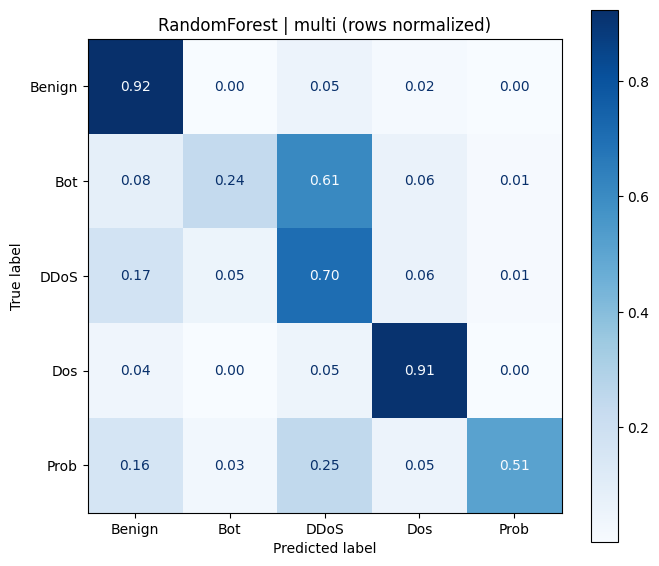

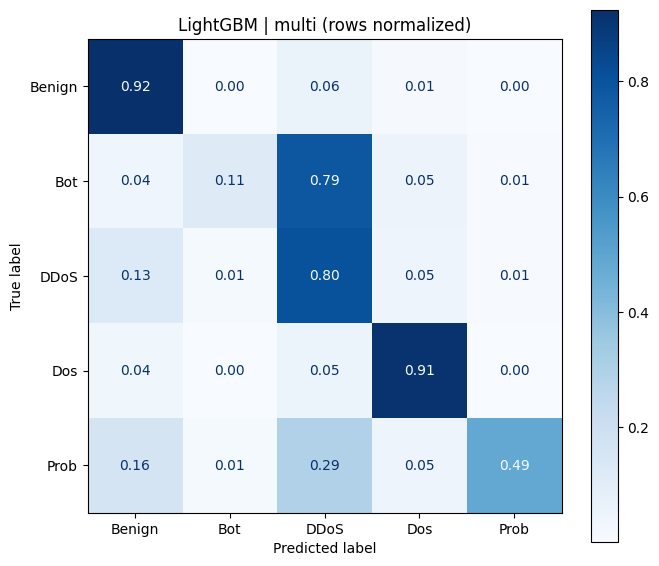

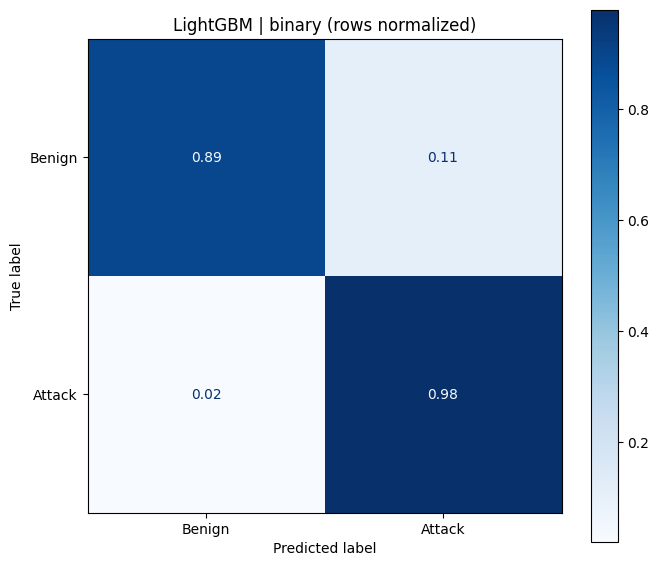

In [27]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

FIG_DIR = "../reports/figures"
os.makedirs(FIG_DIR, exist_ok=True)

cm_models = {
    ("RandomForest", "multi"): (rf_tuned, y_test_multi, None),
    ("LightGBM", "multi"): (lgbm_tuned, y_test_multi, None),
    ("LightGBM", "binary"): (lgbm_bin, y_test_bin, ["Benign", "Attack"]),
}

for (name, task), (model, y_true, labels) in cm_models.items():
    y_pred = model.predict(X_test)
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, normalize="true", values_format=".2f",
        display_labels=labels, cmap="Blues", ax=ax,
    )
    ax.set_title(f"{name} | {task} (rows normalized)")
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/cm_{name}_{task}.png", dpi=150)
    plt.show()

**Reading the matrices:**
- **Bot ↔ DDoS:** most Bot flows are predicted as DDoS: 61% for the tuned Random Forest (Bot recall 0.24) and 79% for the tuned LightGBM (Bot recall 0.11). This is the main weakness of both models.
- **DDoS:** 17% (Random Forest) and 13% (LightGBM) of DDoS flows are predicted as Benign. LightGBM finds more DDoS (recall 0.80 vs 0.70) because it sends more of the Bot flows there.
- **Prob** is confused with DDoS (25-29%) and Benign (16%), recall about 0.5.
- **Benign and Dos** are recognized well by both models (recall 0.91-0.92).
- **Binary task:** most errors are Benign flows predicted as Attack (11%); only 2% of attacks are missed (Benign recall 0.89, Attack recall 0.98).

### Binary score derived from the multi-class models
A multi-class prediction can also be read as a binary one: every prediction other than `Benign` means `Attack`. This shows how well the 5-class models separate attacks from normal traffic, compared with the LightGBM model trained directly on the binary labels (section 4). `label_binary` is exactly `label_multi != "Benign"`, which the first line checks.

In [ ]:
from sklearn.metrics import confusion_matrix

assert ((y_test_multi != "Benign").astype(int) == y_test_bin).all()

binary_preds = {
    "RandomForest tuned (multi -> binary)": (rf_tuned.predict(X_test) != "Benign").astype(int),
    "LightGBM tuned (multi -> binary)": (lgbm_tuned.predict(X_test) != "Benign").astype(int),
    "LightGBM binary (trained on 0/1)": lgbm_bin.predict(X_test),
}

derived_rows = {}
for name, y_pred in binary_preds.items():
    benign_recall, attack_recall = recall_score(y_test_bin, y_pred, labels=[0, 1], average=None)
    derived_rows[name] = {
        "macro_f1": f1_score(y_test_bin, y_pred, average="macro"),
        "accuracy": accuracy_score(y_test_bin, y_pred),
        "benign_recall": benign_recall,
        "attack_recall": attack_recall,
    }
derived_binary = pd.DataFrame(derived_rows).T
display(derived_binary.round(4))

for name, y_pred in binary_preds.items():
    cm = pd.DataFrame(confusion_matrix(y_test_bin, y_pred, labels=[0, 1]),
                      index=["true Benign", "true Attack"], columns=["pred Benign", "pred Attack"])
    print(name)
    display(cm)

### Precision, recall and F1 per class
Recall alone hides the cost of an imbalance method: a model can raise Bot recall by predicting Bot much more often, which lowers Bot precision and the recall of the class it takes the rows from. The table shows all three metrics for every multi-class model on the test set, grouped by class.

In [ ]:
from sklearn.metrics import precision_recall_fscore_support

per_class_models = {
    "RF default": rf_multi,
    "RF balanced": balanced_models[("RandomForest", "multi")],
    "RF tuned": rf_tuned,
    "LGBM default": lgbm_multi,
    "LGBM balanced": balanced_models[("LightGBM", "multi")],
    "LGBM smote": lgbm_smote,
    "LGBM smote_scaled": lgbm_smote_scaled,
    "LGBM tuned": lgbm_tuned,
}
test_pred_multi = {name: model.predict(X_test) for name, model in per_class_models.items()}

frames = []
for name, y_pred in test_pred_multi.items():
    p, r, f, _ = precision_recall_fscore_support(y_test_multi, y_pred, labels=classes, zero_division=0)
    frames.append(pd.DataFrame({"class": classes, "model": name, "precision": p, "recall": r, "f1": f}))

per_class = pd.concat(frames).set_index(["class", "model"])
per_class = per_class.loc[[(c, m) for c in classes for m in per_class_models]]
pd.set_option("display.max_rows", 100)
per_class.round(3)

### Overfitting check: train vs test macro F1
Each model is scored on the same training rows it was fitted on and on the test set. A large gap means the model memorized the training data. The default models are included as a reference (default Random Forest grows every tree to pure leaves).

In [ ]:
fit_check = ["RF default", "RF tuned", "LGBM default", "LGBM tuned"]

overfit = pd.DataFrame({
    "train_macro_f1": [f1_score(y_train_multi, per_class_models[n].predict(X_train), average="macro") for n in fit_check],
    "test_macro_f1": [f1_score(y_test_multi, test_pred_multi[n], average="macro") for n in fit_check],
}, index=fit_check)
overfit["gap"] = overfit["train_macro_f1"] - overfit["test_macro_f1"]
overfit.round(4)

## 8. Results
All rows are written to `reports/results_strong.csv` with the same columns as `results_baseline.csv`, so they can be merged in `04_evaluation.ipynb`.

In [28]:
COLS = ["model", "task", "imbalance", "macro_f1", "accuracy",
        "train_time_s", "predict_ms_per_flow", "notes"]

results_df = pd.DataFrame(results)[COLS]
results_df.to_csv("../reports/results_strong.csv", index=False)

print("Rows:", len(results_df))
results_df.sort_values("macro_f1", ascending=False).reset_index(drop=True)

Rows: 11


,model,task,imbalance,macro_f1,accuracy,train_time_s,predict_ms_per_flow,notes
0,LightGBM,binary,none,0.932245,0.932384,1.78,0.00094,
1,LightGBM,binary,balanced,0.931907,0.932021,1.53,0.00086,
2,RandomForest,binary,balanced,0.912401,0.913171,12.19,0.00221,
3,RandomForest,binary,none,0.912351,0.913124,11.19,0.00224,
4,RandomForest,multi,none,0.673362,0.871922,72.19,0.00575,"tuned {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 30}"
5,LightGBM,multi,none,0.660705,0.881242,19.71,0.02804,"tuned {'subsample': 0.6, 'num_leaves': 63, 'n_estimators': 500, 'min_child_samples': 50, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 0.8}"
6,LightGBM,multi,none,0.646978,0.882378,5.13,0.00301,
7,RandomForest,multi,none,0.644848,0.855589,11.75,0.00280,
8,RandomForest,multi,balanced,0.642982,0.855203,12.31,0.00263,
9,LightGBM,multi,smote,0.622258,0.832371,22.59,0.00279,


## 9. Best model
The demo and the Mininet test predict 5 classes, so the best model is chosen on the multi-class task by test macro F1. The tuned Random Forest has the highest score (0.6734). Its cross-validation score was also the highest (0.6559 vs 0.6520 for LightGBM), so the choice does not depend on the test set. The model is saved with `joblib`. It was trained on `X_train[FEATURE_COLS]`, so inputs must have the same column order. It predicts the text labels (`Benign`, `Dos`, `DDoS`, `Bot`, `Prob`).

The reload check compares `predict_proba` instead of `predict`: with `n_jobs=-1`, a few rows where the tree votes are exactly tied can get a different winner because of ~1e-16 rounding differences in the parallel sum, even for the same model in memory.

In [29]:
import joblib

multi_rows = results_df[results_df["task"] == "multi"].sort_values("macro_f1", ascending=False)
display(multi_rows.head(3))

best = multi_rows.iloc[0]
assert best["model"] == "RandomForest" and best["notes"].startswith("tuned"), "Best model changed, update this cell"
best_model = rf_tuned

assert list(best_model.feature_names_in_) == FEATURE_COLS
print("Classes:", best_model.classes_)

os.makedirs("../models", exist_ok=True)
MODEL_PATH = "../models/best_model.joblib"
joblib.dump(best_model, MODEL_PATH, compress=3)
print(f"File size: {os.path.getsize(MODEL_PATH) / 1e6:.1f} MB")

loaded = joblib.load(MODEL_PATH)
assert np.allclose(loaded.predict_proba(X_test), best_model.predict_proba(X_test))
print("Reloaded model gives the same class probabilities.")

,model,task,imbalance,macro_f1,accuracy,train_time_s,predict_ms_per_flow,notes
9,RandomForest,multi,none,0.673362,0.871922,72.19,0.00575,"tuned {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 0.3, 'max_depth': 30}"
10,LightGBM,multi,none,0.660705,0.881242,19.71,0.02804,"tuned {'subsample': 0.6, 'num_leaves': 63, 'n_estimators': 500, 'min_child_samples': 50, 'max_depth': 10, 'learning_rate': 0.1, 'colsample_bytree': 0.8}"
3,LightGBM,multi,none,0.646978,0.882378,5.13,0.00301,


Classes: ['Benign' 'Bot' 'DDoS' 'Dos' 'Prob']


File size: 205.3 MB


Reloaded model gives the same class probabilities.


### Prediction time for a single flow
`predict_ms_per_flow` from `evaluate()` is the batch prediction time divided by the number of flows. In the demo and the Mininet test flows can arrive one by one, so we also measure predicting one flow at a time (200 flows).

The single-flow time of Random Forest is much higher than LightGBM's. Most of it is the cost of starting parallel jobs (`n_jobs=-1`) for every call, not the 300 trees themselves: in a separate check with `best_model.n_jobs = 1` it dropped to about 6 ms per flow. For one-by-one prediction in the demo, `n_jobs` should be set to 1 after loading the model.

In [30]:
def single_flow_ms(model, X, n=200):
    t0 = time.perf_counter()
    for i in range(n):
        model.predict(X.iloc[[i]])
    return (time.perf_counter() - t0) / n * 1000

tuned = results_df[results_df["notes"].str.startswith("tuned")].set_index("model")
latency = pd.DataFrame({
    "batch_ms_per_flow": tuned["predict_ms_per_flow"],
    "single_flow_ms": [single_flow_ms(rf_tuned, X_test), single_flow_ms(lgbm_tuned, X_test)],
}, index=["RandomForest", "LightGBM"])
latency.round(4)

,batch_ms_per_flow,single_flow_ms
RandomForest,0.0058,44.4035
LightGBM,0.0280,1.4812


## 10. Summary

| Model | Task | Imbalance | Macro F1 | Accuracy |
|---|---|---|---|---|
| LightGBM | binary | none | 0.932 | 0.932 |
| RandomForest (tuned) | multi | none | 0.673 | 0.872 |
| LightGBM (tuned) | multi | none | 0.661 | 0.881 |
| LightGBM | multi | balanced | 0.615 | 0.829 |

- **Best model:** tuned Random Forest for the multi-class task (macro F1 0.673), saved as `models/best_model.joblib`. LightGBM is the best binary model (0.932) and trains in about 2 s.
- **Effect of `balanced`:** for LightGBM it raised Bot recall from 5% to 87% but lowered Bot precision to 0.19 and DDoS recall to 49%, so macro F1 dropped (0.647 → 0.615). SMOTE gave almost the same result and was 4x slower. Random Forest with default (fully grown) trees was not affected.
- **Small classes:** Bot is mostly confused with DDoS and Prob with DDoS and Benign. These classes overlap in the 62 flow features, so imbalance methods only change which class loses, not how well they are separated.
- **Tuning:** limiting tree growth (`min_samples_leaf=2`, `max_depth=30`) reduced overfitting of Random Forest (train macro F1 was 0.99 with default settings) and raised test macro F1 from 0.645 to 0.673.
- **Speed:** in batch, prediction takes 0.006 ms per flow for Random Forest and 0.03 ms for LightGBM. One flow at a time takes about 1.5 ms with LightGBM and about 6 ms with Random Forest when `n_jobs=1` (see section 9).